# IT1244 Group Project: CGM Device Failure Classification

This notebook runs the whole project in order: load the data, analyse it, clean it, split it into 5 folds, train the models and evaluate them. The code it calls is in `src/` (see README.md).

**Team:** Lim Su Ling, Ho Zi Yun Leanne, James Elliot Toh Zhiheng, Chng Lucas

**Task:** multi-class classification. Predict each report's `primary_category` (its IMDRF problem code, e.g. A07 Electrical, A09 Output, A13 Communication) from the free-text `event_description` of FDA MAUDE adverse event reports for continuous glucose monitors (CGMs).

**Model input:** `event_description` only. `brand_name`, `problem_terms`, `imdrf_top_categories` and `manufacturer_narrative` are used for analysis, never as model input.

| Section | Owner |
|---|---|
| 1. Loading | Suling, James |
| 2. Dataset analysis | Leanne |
| 3. Data cleaning | Suling |
| 4. Folds (train/test rotation) | Suling |
| 5.1 TF-IDF + LR | James |
| 5.2 BiLSTM, 5.3 transformer | Suling |
| 6. Evaluation (incl. majority and phrase-lookup baselines) | Lucas |

## References and how we address their limitations

1. **Wang, Kang & Gong (2019), MEDINFO 2019.** *Generating a Health Information Technology Event Database from FDA MAUDE Reports.* [Link](https://ebooks.iospress.nl/pdf/doi/10.3233/SHTI190350). TF-IDF models (LR, SVM, NB, RF) vs a CNN on 5,588 MAUDE reports; LR alone reached F1 0.859, the best ensemble 0.870.
   *Limitations and our approach:* their models ignore word context, the data contained duplicates, and it was artificially balanced. We use TF-IDF + LR only as our baseline and test whether models that read word order (BiLSTM) and context (transformer) do better; we keep all copies of a description in the same fold; and we keep the real class imbalance, handling it with class weights and macro-F1.
2. **Li et al. (2024), Frontiers in Computational Neuroscience.** [Link](https://www.frontiersin.org/journals/computational-neuroscience/articles/10.3389/fncom.2024.1476164/full). BiLSTM with attention for harm vs no-harm classification of 4,568 da Vinci surgical-robot MAUDE reports; F1 85.37, above plain BERT (78.61).
   *Limitations and our approach:* a small, single-device, binary dataset whose authors note performance on larger data is unvalidated. We test a BiLSTM (with attention) on ~380k CGM reports with a multi-class label, using dropout and early stopping to limit overfitting.
3. **Luschi, Nesi & Iadanza (2023), Heliyon.** [Link](https://doaj.org/article/98416b10bbbe438aa6e6a6393225e069). Fine-tuned ClinicalBERT on 3,075 expert-labelled MAUDE reports to detect health-IT adverse events, with explainability.
   *Limitations and our approach:* a small dataset with no comparison against cheaper baselines. We fine-tune DistilBERT / Bio_ClinicalBERT on CGM reports and compare it directly with TF-IDF + LR and the BiLSTM on the same folds and metrics, to see whether the extra compute is worth it.

Background: [CGM failure modes in MAUDE](https://pmc.ncbi.nlm.nih.gov/articles/PMC11688675/)

**Code attribution:** the transformer uses the Hugging Face `transformers` library and pretrained weights (`distilbert-base-uncased`, `emilyalsentzer/Bio_ClinicalBERT`).

## 0. Setup

- **Locally:** install the packages with `pip install -r requirements.txt`.
- **On Google Colab** (needed for the GPU): the first code cell clones this project's public GitHub repository into `/content` and pulls the latest pushed code. It does nothing locally or when `src/` is already in the working folder.

The dataset is downloaded into `data/` the first time it is loaded (see `data/README.md`).

1. To **reproduce our results without training**, download the weights (see `links.txt`) into `weights/` and set `TRAIN = False`.
2. Run all cells top to bottom.

On Colab, files are saved in the server's `/content` folder, which is wiped when the runtime disconnects: copy `weights/` back after training (in VS Code: *Colab: Mount Server To Workspace*). With `TRAIN = True`, a turn whose model file is already in `weights/` is loaded instead of retrained, so an interrupted run continues where it stopped.

In [1]:
## Google Colab only: get the code from GitHub. Does nothing locally or when src/ is already here.
import os
import sys

REPO_URL = "https://github.com/AsElle06/IT1244-Group-Project.git"
REPO_DIR = "/content/IT1244-Group-Project"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

if IN_COLAB and not os.path.exists("src"):
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}
    os.chdir(REPO_DIR)
if IN_COLAB:
    if os.path.exists(".git"):
        # Latest pushed code. If this pulls new code after src/ was already imported,
        # restart the kernel and run the notebook again so the new code is used.
        !git pull -q
    !pip install -q -r requirements.txt
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())  # so `from src import ...` finds the project
print("working folder:", os.getcwd())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 38.4 MB/s eta 0:00:00a 0:00:01
working folder: /content/IT1244-Group-Project


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.analysis import eda
from src.data import cleaning, loading, splitting
from src.evaluation import cross_validation, metrics
from src.evaluation.baseline import MajorityBaseline
from src.helpers import device_info, get_device, set_seed
from src.models.bilstm import BiLSTMClassifier, tokenize
from src.models.torch_training import plot_training_curves
from src.models.tfidf_lr import TfidfLR
from src.models.transformer import CLINICAL_BERT, DISTILBERT, TransformerClassifier


TRAIN = False    # True while training on Colab; set back to False before the final submission (False: load the saved weights from weights/)

set_seed(config.SEED)
device = get_device()
config.WEIGHTS_DIR.mkdir(exist_ok=True)
print(device_info())

cuda: Tesla T4


## 1. Load data (Suling, James)

In [3]:
# Downloads the dataset into data/ first if it is not there yet (see data/README.md)
df = loading.load_reports()
print(df.shape)
df.head()

Retrieving folder contents


Processing file 1W3i69D4WqnDx5Glff4jnidDFu_RxMAxi cgm_reports_dataset.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1W3i69D4WqnDx5Glff4jnidDFu_RxMAxi
From (redirected): https://drive.google.com/uc?id=1W3i69D4WqnDx5Glff4jnidDFu_RxMAxi&confirm=t&uuid=11380e87-d6ef-4eb6-a617-3d565570e254
To: /content/IT1244-Group-Project/data/cgm_reports_dataset.csv
100%|██████████| 300M/300M [00:06<00:00, 49.7MB/s] 
Download completed


(379886, 10)


,mdr_report_key,brand_name,event_description,manufacturer_narrative,problem_codes,problem_terms,imdrf_top_categories,imdrf_top_category_names,primary_category,primary_category_name
0,21050673,DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4).,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
1,21050676,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4).,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
2,21050677,DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)94). 3004753838-2024-341468 WAS REP...,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
3,21050678,DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4). B5: DESCRIBE EVENT OR PROBLEM ...,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem
4,21050679,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED. N...,(B)(4). (B)(4).,3283,Wireless Communication Problem,A13,Communication or Transmission Problem,A13,Communication or Transmission Problem


## 2. Dataset analysis on the whole dataset (Leanne)

This section analyses all 379,886 reports, before the folds are made (section 4), because the folds depend on what it finds: which labels are missing or too rare to keep (2.1), and which reports are copies that must stay in the same fold (2.4). The whole dataset also gives the true distributions for the report.

No test report leaks into the models because nothing here is fitted: the analysis only sets rules (drop NONE, merge A24–A27, mask dates and IDs, keep copies of a text together, cap copies; summary in 2.10). Everything the models learn — TF-IDF vocabulary, class weights, network weights — comes from each turn's training folds only (section 5).

### 2.1 Class counts
Informs: class weights, which rare classes to merge, and why macro-F1 is the main metric.

`distinct_texts` counts the different descriptions in each class after removing dates, IDs, numbers and redaction markers (`cleaning.template_key`, see 2.4).

,count,share_%,distinct_texts,expected_test_reports
primary_category,,,,
A09,112521,29.620,15629,22504.2
A13,102838,27.071,4576,20567.6
A05,73061,19.232,3703,14612.2
A16,47351,12.465,3096,9470.2
A11,19912,5.242,398,3982.4
A04,10625,2.797,1488,2125.0
A07,5606,1.476,881,1121.2
A27,4488,1.181,1918,897.6
A24,1330,0.350,1289,266.0


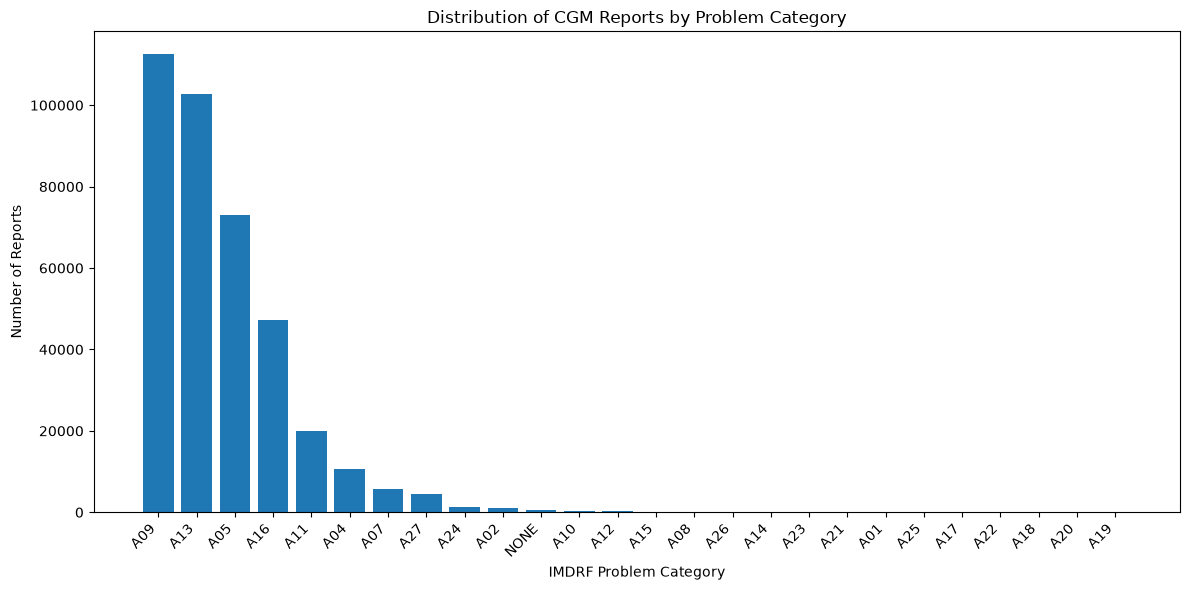

The top 4 most common classes account for 88.39% of the reports


In [3]:
class_summary = eda.class_counts(df[config.LABEL_COL], df[config.TEXT_COL])
class_summary["expected_test_reports"] = (class_summary["count"] * config.TEST_SIZE).round(1)
display(class_summary.round(3))

eda.plot_class_counts(df[config.LABEL_COL], save_as="class_counts.png")

# Percentage of reports in the four largest categories
top_4_share = class_summary["share_%"].head(4).sum()
print(f"The top 4 most common classes account for {top_4_share:.2f}% of the reports")

In [4]:
## Is NONE a real category? Check whether its reports have any IMDRF code or problem term
none_reports = df[df[config.LABEL_COL] == "NONE"]
no_label_info = none_reports[[config.IMDRF_COL, "problem_terms"]].isna().all(axis=1)

print(f"NONE reports: {len(none_reports)}")
print(f"with no IMDRF code and no problem term: {no_label_info.mean():.0%}")

NONE reports: 473
with no IMDRF code and no problem term: 100%


In [5]:
## Classes too small for a reliable F1
# A24-A27 are merged first (course README: "Unknown / No device problem") and NONE is dropped;
# then every class expected to have fewer than config.MIN_CLASS_COUNT training reports goes into OTHER.
labels_after = df[config.LABEL_COL].replace({code: "A24-A27" for code in ["A24", "A25", "A26", "A27"]})
labels_after = labels_after[labels_after != "NONE"]

after_merge = eda.class_counts(labels_after)
after_merge["expected_train_reports"] = (after_merge["count"] * (1 - config.TEST_SIZE)).round(1)
after_merge["expected_test_reports"] = (after_merge["count"] * config.TEST_SIZE).round(1)
to_other = after_merge[after_merge["expected_train_reports"] < config.MIN_CLASS_COUNT]

display(after_merge.round(3))
print(f"Merged into OTHER: {', '.join(to_other.index)} ({to_other['count'].sum()} reports)")
print(f"Classes left: {len(after_merge) - len(to_other) + 1}")

,count,share_%,expected_train_reports,expected_test_reports
primary_category,,,,
A09,112521,29.657,90016.8,22504.2
A13,102838,27.105,82270.4,20567.6
A05,73061,19.256,58448.8,14612.2
A16,47351,12.480,37880.8,9470.2
A11,19912,5.248,15929.6,3982.4
A04,10625,2.800,8500.0,2125.0
A24-A27,5857,1.544,4685.6,1171.4
A07,5606,1.478,4484.8,1121.2
A02,936,0.247,748.8,187.2


Merged into OTHER: A15, A08, A14, A23, A21, A01, A17, A22, A18, A20, A19 (226 reports)
Classes left: 12


#### Observations
The distribution of CGM adverse event reports across IMDRF problem categories is highly imbalanced. A09, A13, A05 and A16 account for 88.39% of reports, while 10 categories have fewer than 20 reports each and A17, A18, A19, A20 and A22 have only one or two.

Report counts also overstate how much varied text a class has. A13 has 102,838 reports but only 4,576 distinct descriptions, and A11 has 19,912 reports but only 398: most of their reports are copies of a few templates (see 2.4).

All 473 NONE reports have no IMDRF code and no problem term, so NONE is a missing label, not a problem category.

#### Interpretation
These class imbalances present several challenges for our supervised machine learning model. Models trained on this dataset will learn patterns associated with the frequent categories more effectively than those of minority categories. Consequently, models may show high overall accuracy but perform poorly on less frequently reported problems.

Small classes are a problem for evaluation as well as training. Having at least 5 reports only guarantees one report per cross-validation fold; it does not make the class's F1 reliable. With a 20% test set, a class with 15 reports gets about 3 test reports, so a single misclassified report changes its recall by a third, and macro-F1 weights that noisy score as much as A09's.

#### Decisions (applied in section 3, cleaning)
- **Drop NONE** (473 reports): the label is missing.
- **Merge A24–A27** into one class, `A24-A27` (5,857 reports), as the course README's label table does ("Unknown / No device problem"): all four codes mean no specific device problem was identified.
- **Merge classes with fewer than `config.MIN_CLASS_COUNT` = 150 training reports into OTHER**: A15, A08, A14, A23, A21, A01, A17, A22, A18, A20 and A19 (226 reports, about 45 in the test set together). A10 and A12 (about 48 test reports each) stay separate. This leaves 12 classes. Which classes fall below the threshold is decided once on the whole dataset (section 3), so every fold has the same 12 classes.

#### Evaluation Metric
Given the substantial class imbalance, we chose macro-F1 as the primary evaluation metric as it assigns equal importance to each class, regardless of its frequency. This ensures that poor performance on the minority categories is not obscured by strong performance on the majority categories, allowing a more balanced assessment of classification performance across the IMDRF problem categories.

### 2.2 Text length
Informs: the maximum input length for the BiLSTM and transformer.

In [6]:
display(eda.length_percentiles(df[config.TEXT_COL]))

p50     59.0
p90    107.0
p95    158.0
p99    249.0
Name: event_description, dtype: float64

##### Interpretation of percentiles
The results present that 50% of reports contain approximately 59 words or fewer, 90% contain approximately 107 words or fewer, 95% with 158 words or fewer and 99% containing approximately 249 words or fewer.
These suggest that choosing a maximum input length of approximately 160 words would preserve complete descriptions for about 95% of reports, while 256 words would preserve complete descriptions for at least 99%.


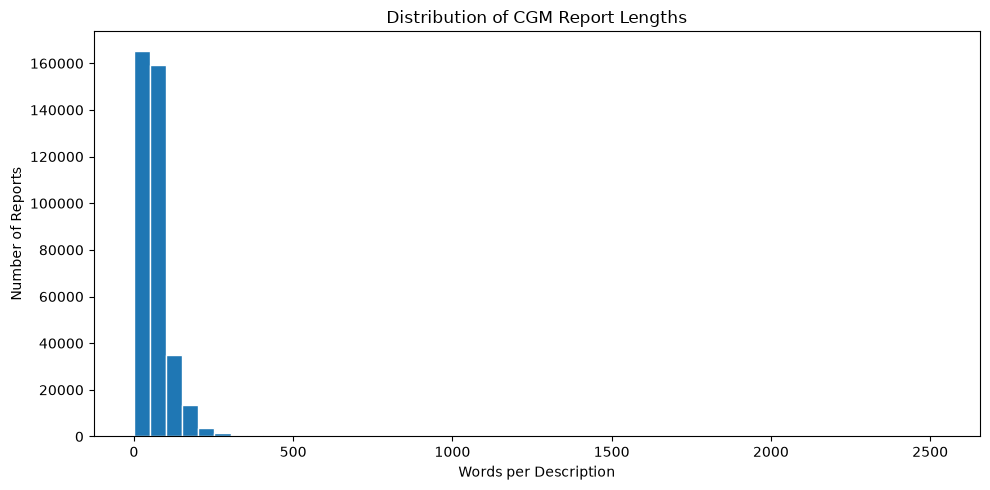

In [7]:
eda.plot_length_hist(df[config.TEXT_COL], save_as="length_hist.png")

##### Interpretation of histogram

The plot is highly right-skewed, showing that most reports are concentrated at relatively low word counts, while a small number extend into the much longer tail. This is consistent with the percentile results, with the median of 59 words and the 99th percentile of 249 words.

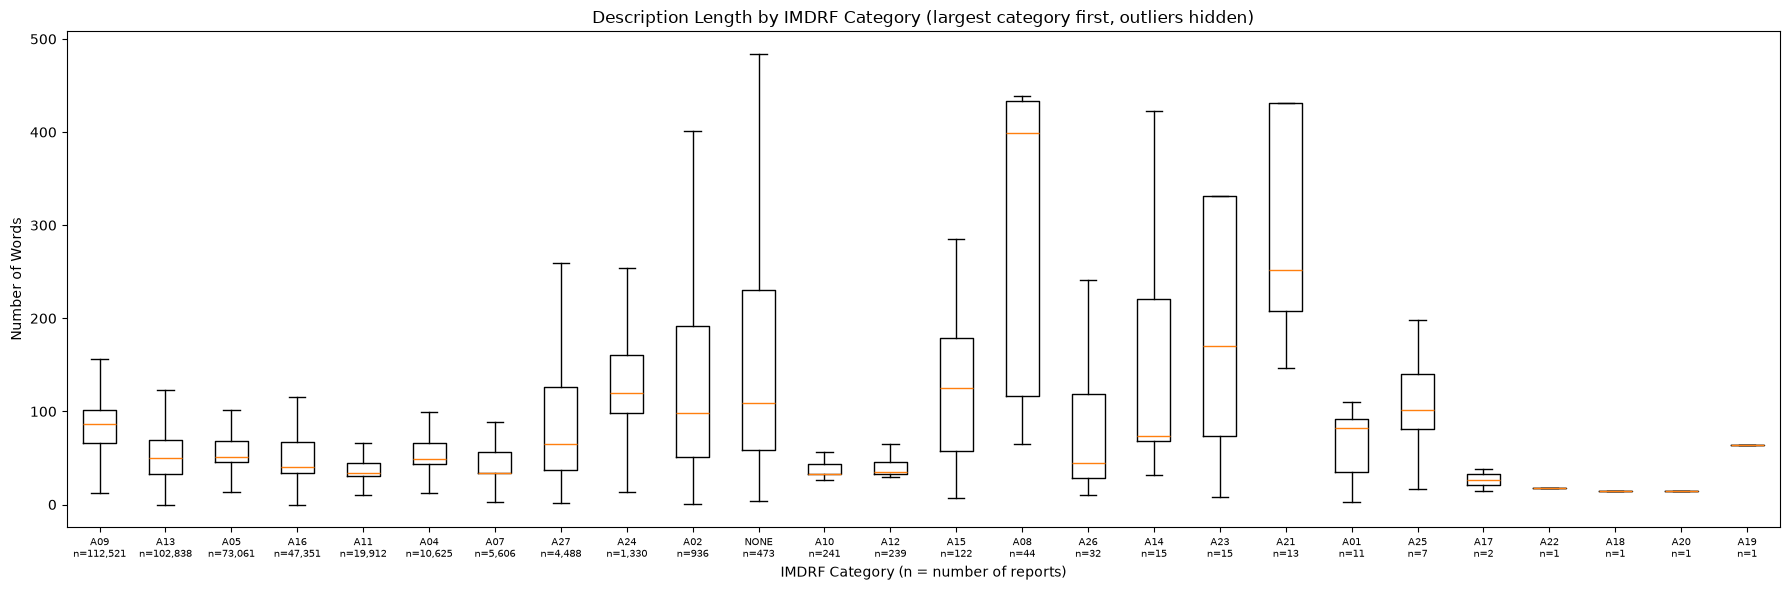

In [8]:
eda.plot_length_by_class(df, save_as="length_by_class.png")

##### Interpretation of box plot
The box plots show how description lengths differ across problem categories, largest category first, with the number of reports under each box.
The large categories have similar typical lengths (medians 34–86 words); A09 is the longest of them, partly because it contains most of the longer Abbott reports (see the length by brand below).
Categories such as A08, A21 and A23 look much longer (medians 170–399 words) and A10, A11, A12 and A17 shorter. However, A08, A21 and A23 have only 44, 13 and 15 reports, and several boxes further right describe one or two reports, so these differences should not be treated as reliable category patterns.
Using the same maximum input length for every category may disproportionately truncate reports from categories with longer descriptions.

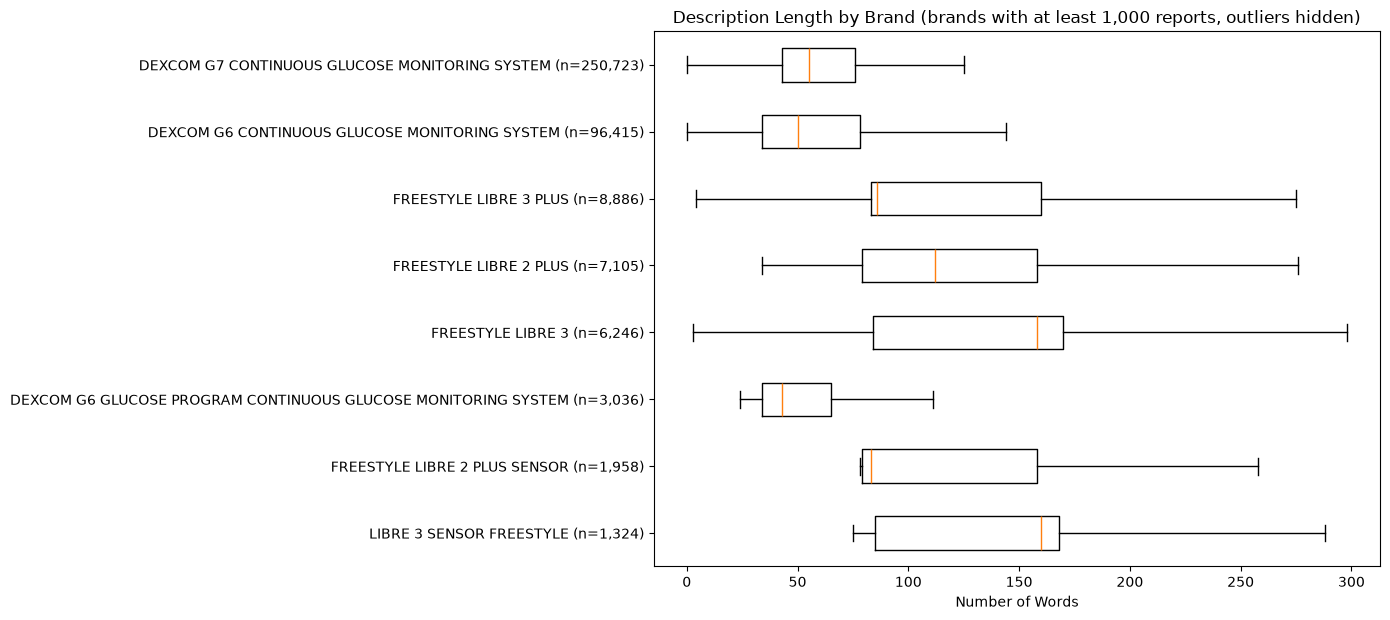

,reports,text_repeated_%,median_words,median_words_cleaned,over_128_words_%,over_128_words_cleaned_%
Abbott,27402,45.70,135.5,85.0,50.66,9.17
Dexcom,352408,0.03,53.0,53.0,3.39,3.32
Other,76,0.00,119.0,124.0,44.74,48.68


All reports within 128 / 256 words after cleaning: 96.25% / 99.24%


In [9]:
## Length by brand, before and after cleaning (section 3 keeps one copy of a description that repeats itself)
eda.plot_length_by_brand(df, save_as="length_by_brand.png")

raw_text = df[config.TEXT_COL].fillna("")
words = raw_text.str.split().str.len()
clean_words = raw_text.map(cleaning.clean_text).str.split().str.len()
repeated = raw_text.map(cleaning.remove_repeated_text) != raw_text
family = eda.brand_family(df[config.BRAND_COL])

display(pd.DataFrame({
    "reports": family.value_counts(),
    "text_repeated_%": repeated.groupby(family).mean() * 100,
    "median_words": words.groupby(family).median(),
    "median_words_cleaned": clean_words.groupby(family).median(),
    "over_128_words_%": (words > 128).groupby(family).mean() * 100,
    "over_128_words_cleaned_%": (clean_words > 128).groupby(family).mean() * 100,
}).round(2))
print(f"All reports within 128 / 256 words after cleaning: {(clean_words <= 128).mean():.2%} / {(clean_words <= 256).mean():.2%}")

##### Interpretation of length by brand
Abbott (FreeStyle Libre) reports look much longer than Dexcom reports (median 135.5 vs 53 words), but mostly because 45.70% of them contain their whole description two or more times in a row. On the raw text, a maximum length of 128 words would truncate 50.66% of Abbott reports; cleaning keeps one copy of a repeated description (section 3), after which the Abbott median is 85 words and only 9.17% of Abbott reports (3.32% of Dexcom) exceed 128 words. Across all reports, 96.25% fit in 128 words after cleaning and 99.24% in 256, so the raw-text percentages below understate how much each length keeps.

These graphical data brings about some implications that we would have to consider.

In [10]:
## Determining how much text different input lengths can retain

# Calculate word counts for each description
word_lengths = (
    df[config.TEXT_COL]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Compare possible maximum input lengths
max_lengths = [64, 128, 256, 384, 512]

results = []

for length in max_lengths:

    retained = (word_lengths <= length).mean() * 100
    truncated = (word_lengths > length).mean() * 100

    results.append({
        "Max Length": length,
        "Reports Fully Retained (%)": round(retained, 2),
        "Reports Requiring Truncation (%)": round(truncated, 2)
    })

length_comparison = pd.DataFrame(results)

display(length_comparison)

,Max Length,Reports Fully Retained (%),Reports Requiring Truncation (%)
0,64,52.75,47.25
1,128,93.20,6.80
2,256,99.09,0.91
3,384,99.73,0.27
4,512,99.89,0.11


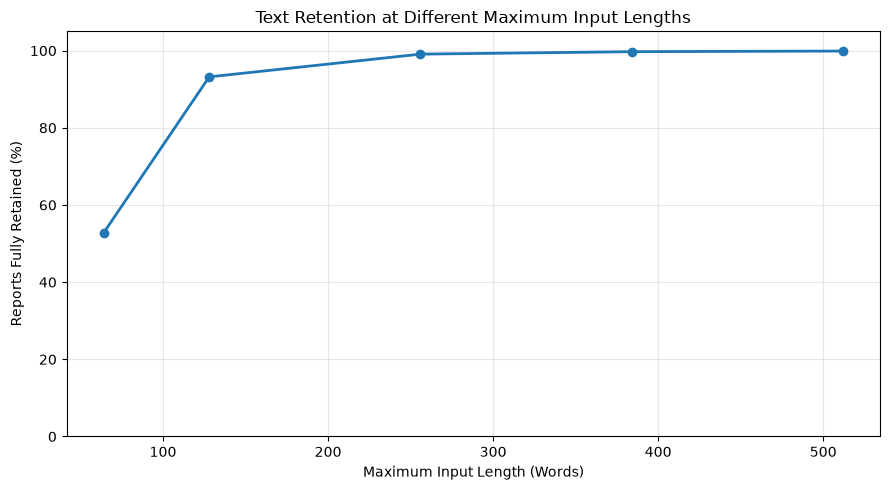

In [11]:
## Visualising the input length trade-off

plt.figure(figsize=(9, 5))

plt.plot(
    length_comparison["Max Length"],
    length_comparison["Reports Fully Retained (%)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Maximum Input Length (Words)")
plt.ylabel("Reports Fully Retained (%)")
plt.title("Text Retention at Different Maximum Input Lengths")

plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    config.FIGURES_DIR / "length_retention.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### Observations
The analysis of text retention at different maximum input lengths reveals that increasing the sequence length substantially improves the proportion of CGM event descriptions that can be retained without truncation.

At 64 words, only 52.75% of reports can be fully retained. This means that 47.25% would require truncation, thus potentially removing information relevant to classifying CGM device problems. Therefore having 64 words is unlikely to be an appropriate maximum input length without further evidence. Increasing the limit to 128 words raises this proportion to 93.20%, while a maximum length of 256 words accommodates 99.09% of reports. Increasing to anything beyond 256 words only provides diminishing returns. For example, increasing from 256 to 512 words would lead to an improvement of only 99.89% − 99.09% = 0.80 percentage points.
The text-retention curve shows the same plateau beyond approximately 256 words.

#### Interpretation
The findings highlight the trade-off between information retention and computational efficiency. 
Selecting a shorter maximum input length would reduce the computational requirements, but it may result in the truncation of longer descriptions, potentially removing contextual information that is important for a more accurate classification. 
Conversely, selecting an excessively long maximum input length would increase memory consumption and computational overhead, while only providing relatively small improvements in text retention.
Increasing beyond 256 words may not be computationally justified unless the additional information contributes meaningfully to the classification performance. 

#### Implications for Model Development
##### BiLSTM:
Based on the observed word-length distribution, we will investigate the maximum sequence lengths of 128 and 256 tokens. While 128 only accommodates 93.20% of descriptions, and increasing the limit to 256 words accommodates 99.09%, our final choice of maximum sequence length will be determined by balancing computational efficiency, text retention and cross-validation performance. These percentages are for the raw text: after cleaning, 96.25% of reports fit in 128 words and 99.24% in 256 (see the length by brand above), so 128 is likely enough. 

##### Transformer:
Since DistilBERT and Bio_ClinicalBERT employ subword tokenisation, the word-length distribution alone is insufficient to determine the optimal maximum input length. 
Thus, the actual token-length distribution will be examined using the selected transformer’s tokeniser. Candidate lengths will subsequently be evaluated based on text retention, computational requirement and classification performance. 

### 2.3 Empty or very short descriptions
Informs: whether cleaning drops these reports or keeps them.

In [12]:
eda.short_description_summary(df[config.TEXT_COL])

,reports,share_%
threshold,,
<= 0 words,4,0.001053
<= 3 words,48,0.012635
<= 5 words,74,0.019480
<= 10 words,123,0.032378


In [13]:
# Calculate word counts
word_lengths = (
    df[config.TEXT_COL]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Count descriptions by length
empty_reports = (word_lengths == 0).sum()
very_short_reports = ((word_lengths >= 1) & (word_lengths <= 3)).sum()
short_reports = ((word_lengths >= 4) & (word_lengths <= 10)).sum()

print("Empty descriptions:", empty_reports)
print("1–3 words:", very_short_reports)
print("4–10 words:", short_reports)

Empty descriptions: 4
1–3 words: 44
4–10 words: 75


##### Observations:
Only 4 reports (0.0011%) contain empty descriptions, while 48 reports (0.0126%) contain three words or fewer. Furthermore, only 123 reports (0.0324%) contain ten words or fewer.

The results show that only 0.0324% of reports contain 10 words or fewer. Therefore, short descriptions represent a negligible proportion of our dataset.

In [14]:
# Extract reports containing 1–3 words
very_short_df = df[
    (word_lengths >= 1) & (word_lengths <= 3)
]

# Display examples
display(
    very_short_df[
        [config.TEXT_COL, config.LABEL_COL]
    ].head(20)
)

,event_description,primary_category
7759,EARLY SENSOR EXPIRATION.,A16
8696,SIGNAL LOSS.,A13
18979,SIGNAL LOSS.,A13
23125,PHYSICAL DAMAGE.,A27
26970,APPLICATOR DEPLOYMENT.,A04
29937,EARLY SENSOR EXPIRATION.,A16
32216,PHYSICAL DAMAGE.,A04
32500,SIGNAL LOSS.,A13
34632,ALERT/NOTIFICATION SETTINGS.,A16
36476,CGM ACCURACY,A09


#### Observations:
As we examine the non-empty short descriptions, several reports were found to contain potentially informative keywords such as “SIGNAL LOSS”, “EARLY SENSOR EXPIRATION" and “CGM ACCURACY”. Such keywords indicate the nature of the reported problems.
There is also the issue of ambiguity. For example, the description “PHYSICAL DAMAGE” is found to be associated with two different IMDRF categories, A04 and A27.


#### Interpretation:
The low proportion of empty and short descriptions suggest that missing textual information is not significant in terms of prevalence. Nonetheless, empty descriptions provide no usable textual features for classification, and may introduce noise into the training process.
Conversely, non-empty short descriptions may still contain highly informative terms associated with specific CGM problem categories. Removing them could result in unnecessary information loss. 
Identical descriptions associated with different labels may also lead to classification challenges, as our models rely exclusively on textual information to predict the primary category.

#### Implications for Model Development:
With these findings, we will consider removing the 4 empty reports and retain the non-empty short descriptions. Any further filtering will be considered based on the information content of the descriptions and its implications for model performance. 
In addition, we will also investigate reports with identical descriptions but different labels during the next duplicate analysis to identify any potential inconsistencies in the classification labels.


### 2.4 Duplicate and near-duplicate descriptions
Informs: how the folds keep copies of a description together.

Duplicates are counted twice: on the exact text, and on the **normalised** text (`cleaning.template_key`: one copy kept of a description that repeats itself, upper-cased, with redaction markers such as "(B)(6)", every token containing a digit — dates, years, IDs, glucose values — and punctuation removed).

In [15]:
duplicate_stats, top_templates = eda.duplicate_summary(df)
display(duplicate_stats, top_templates)

reports                                  379886
reports with non-empty descriptions      379882
unique descriptions (exact)               71174
reports sharing their exact text         319046
exact texts with >1 label                   701
unique descriptions (normalised)          33198
reports sharing their normalised text    353818
normalised texts with >1 label              717
dtype: int64

,count,labels
text,,
IT WAS REPORTED THAT A DETACHED OR MISSING SENSOR WIRE OCCURRED THE SENSOR WAS INSERTED INTO THE ARM ON NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,27470,"{'A05': 27394, 'A04': 37, 'A12': 12, 'A16': 11..."
IT WAS REPORTED THAT A SIGNAL LOSS OCCURRED NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,27021,"{'A13': 27005, 'A09': 7, 'A05': 5, 'A16': 2, '..."
IT WAS REPORTED THAT AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR CGM AND THE BLOOD GLUCOSE BG METER OCCURRED THE SENSOR WAS INSERTED INTO THE ARM ON DATA WAS EVALUATED AND THE ALLEGATION WAS UNDETERMINED THE PROBABLE CAUSE COULD NOT BE DETERMINED VIA DATA THE REPORTED GLUCOSE VALUES FALL WITHIN THE D ZONE OF THE PARKES ERROR GRID THE DATA INVESTIGATION DID NOT FIND BLOOD GLUCOSE CALIBRATION VALUES TO COMPARE TO CGM VALUES DURING THE REPORTED SENSOR SESSION OR THE CALIBRATIONS DURING THE REPORTED SENSOR SESSION WERE IN ACCURATE RANGE PER DEVICE SPECIFICATIONS NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,10259,"{'A09': 10246, 'A05': 11, 'A16': 1, 'A08': 1}"
IT WAS REPORTED THAT SIGNAL LOSS OCCURRED PERFORMANCE DATA WAS REVIEWED THE ALLEGATION WAS CONFIRMED DUE TO THE FINDING OF SIGNAL LOSS OVER AN HOUR WITHIN THE INVESTIGATION WINDOW THE PROBABLE CAUSE WAS THE TRANSMITTER AND APP WERE UNABLE TO ESTABLISH A CONNECTION NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,9706,"{'A13': 9699, 'A05': 2, 'A11': 2, 'A07': 1, 'A..."
IT WAS REPORTED THAT A TRANSMITTER BATTERY ISSUE OCCURRED NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,9181,"{'A09': 9107, 'A13': 63, 'A27': 7, 'A11': 1, '..."
IT WAS REPORTED THAT SIGNAL LOSS OCCURRED PERFORMANCE DATA WAS REVIEWED THE ALLEGATION WAS CONFIRMED DUE TO THE FINDING OF SIGNAL LOSS OVER AN HOUR WITHIN THE INVESTIGATION WINDOW THE PROBABLE CAUSE COULD NOT BE DETERMINED NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,7396,"{'A13': 7393, 'A11': 2, 'A16': 1}"
IT WAS REPORTED THAT A NO READINGS SENSOR ERROR BRIEF SENSOR ISSUE OCCURRED PERFORMANCE DATA WAS REVIEWED NO READINGS SENSOR ERROR BRIEF SENSOR ISSUE WAS NOT FOUND WITHIN THE INVESTIGATION WINDOW THE ALLEGATION WAS NOT CONFIRMED HOWEVER SIGNAL LOSS OVER AN HOUR WAS FOUND IN CONNECTION TO THE REPORTED ALLEGATION THE PROBABLE CAUSE OF THE SIGNAL LOSS WAS DETERMINED TO BE THE TRANSMITTER AND APP WERE UNABLE TO ESTABLISH A CONNECTION NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,7337,"{'A13': 7336, 'A16': 1}"
IT WAS REPORTED THAT A DEXCOM APP CRASH OCCURRED DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED THE PROBABLE CAUSE COULD NOT BE DETERMINED NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,7329,"{'A11': 7245, 'A13': 58, 'A16': 24, 'A04': 1, ..."
IT WAS REPORTED THAT AN ALERT NOTIFICATION SETTINGS ISSUE OCCURRED NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED NO INJURY OR MEDICAL INTERVENTION WAS REPORTED,6496,"{'A16': 6466, 'A27': 12, 'A11': 7, 'A09': 4, '..."


In [16]:
## Percentage of reports that share their description with another report
total_reports = duplicate_stats["reports with non-empty descriptions"]

for kind in ["exact", "normalised"]:
    shared = duplicate_stats[f"reports sharing their {kind} text"]
    print(f"Reports sharing their {kind} text: {shared:,} ({shared / total_reports * 100:.2f}%)")

Reports sharing their exact text: 319,046 (83.99%)
Reports sharing their normalised text: 353,818 (93.14%)


##### Observations:
The results reveal a large amount of duplication. Of the 379,882 non-empty reports, 319,046 (83.99%) share their exact text with another report, and there are only 71,174 distinct descriptions.

Exact matching still undercounts the copies, because many reports are the same template with a different date, ID, glucose reading or redaction marker (e.g. "INSERTED INTO THE ARM ON (B)(6) 2025" vs "ON(B)(6) 2025"), or the same text written twice. After normalising there are only **33,198** distinct descriptions, and 353,818 reports (93.14%) share theirs with another report. The ten most common templates alone cover 31.2% of the dataset.

717 normalised descriptions are used with two or more primary categories.

In [17]:
# Prepare normalised descriptions and labels
temp = df[[config.TEXT_COL, config.LABEL_COL]].copy()

temp["clean_text"] = cleaning.template_key(temp[config.TEXT_COL])

temp = temp[temp["clean_text"] != ""]

# Counting distinct labels per description
label_counts = (
    temp.groupby("clean_text")[config.LABEL_COL]
    .nunique(dropna=False)
)

# Find descriptions with conflicting labels
conflicting_texts = label_counts[label_counts > 1].index

# Find reports using those descriptions
conflicting_reports = temp[
    temp["clean_text"].isin(conflicting_texts)
]

print("Descriptions with conflicting labels:", len(conflicting_texts))

print("Reports affected:", len(conflicting_reports))

print(
    "Percentage of non-empty reports affected:",
    round(len(conflicting_reports) / len(temp) * 100, 2),
    "%"
)

# Number of reports for each description-label combination
label_distribution = (
    temp.groupby(["clean_text", config.LABEL_COL],
                 dropna=False)
    .size()
    .reset_index(name="count")
)

# Total reports for each unique description
total_per_text = (
    label_distribution.groupby("clean_text")["count"]
    .sum()
)

# Most frequent label count for each description
majority_per_text = (
    label_distribution.groupby("clean_text")["count"]
    .max()
)

# Reports with a label different from the majority label
minority_reports = (
    total_per_text - majority_per_text
).sum()

print("Reports differing from majority label:", minority_reports)

print(
    "Percentage of non-empty reports:",
    round(minority_reports / len(temp) * 100, 2),
    "%"
)

Descriptions with conflicting labels: 717
Reports affected: 263844
Percentage of non-empty reports affected: 69.45 %


Reports differing from majority label: 2758
Percentage of non-empty reports: 0.73 %


##### Observations:
The 717 descriptions with conflicting labels appear in 263,844 reports (69.45% of non-empty reports), because most of the large templates carry a few stray labels. However, only 2,758 reports (0.73%) have a label different from the most common label of their description, so almost all reports share their description's dominant label.

#### Interpretation:
The large amount of duplicated descriptions presents a significant risk of data leakage. If copies of a description appear in both the training and test sets, the model may recognise previously seen text rather than generalise to unseen descriptions, and evaluation scores such as macro-F1 would be overestimated. Matching on exact text is not enough: copies of the same template that differ only in a date, an ID or a glucose value would still end up on both sides.

Descriptions associated with multiple labels may also introduce ambiguity into the classification task. Since our models rely solely on event_description as input, they cannot distinguish reports with the same text but different primary categories.
Nonetheless, the small proportion of reports (0.73%) differing from their description's majority label suggests that disagreements are limited at the dataset level. Such differences may come from contextual information not present in the descriptions, and do not necessarily indicate incorrect labelling.

#### Implications for Model Development:
To minimise data leakage, all copies of the same cleaned description are kept in one fold (section 4), so a model is never tested on a text it trained on.
We will also investigate the impact of conflicting labels, particularly on minority categories, and consider whether additional handling is justified based on their prevalence, potential classification ambiguity and validation performance, rather than simply removing or relabelling these reports.
These measures aim to improve the reliability of model evaluation and provide a more meaningful assessment of the three models' ability to generalise to unseen CGM reports.

### 2.5 Template vs free text
Informs: what "doing well" means on this dataset, which baseline the models must beat, and how section 6 breaks down the results.

The reports come in three writing styles:
1. **Dexcom fill-in-the-blank** (about 90% of reports): "IT WAS REPORTED THAT A **SIGNAL LOSS** OCCURRED. NO PRODUCT OR DATA WAS PROVIDED FOR EVALUATION. … NO INJURY OR MEDICAL INTERVENTION WAS REPORTED." Only the bold **complaint phrase** changes; the rest is standard process text that appears in every class.
2. **Abbott templates**: "A CUSTOMER REPORTED RECEIVING ERRONEOUS GLUCOSE RESULTS FROM AN ABBOTT DIABETES CARE DEVICE… PARKES ERROR GRID… C ZONE…", almost all A09.
3. **Free text**: patients or clinicians writing in their own words ("MY DEXCOM G7 SENSOR CONTINUES TO GIVE INACCURATE READINGS…"), a small minority.

A report's **text frequency** is how many reports share its normalised text (`cleaning.template_key`): 10+ copies (a template), 2–9 copies, or once (one-off text).

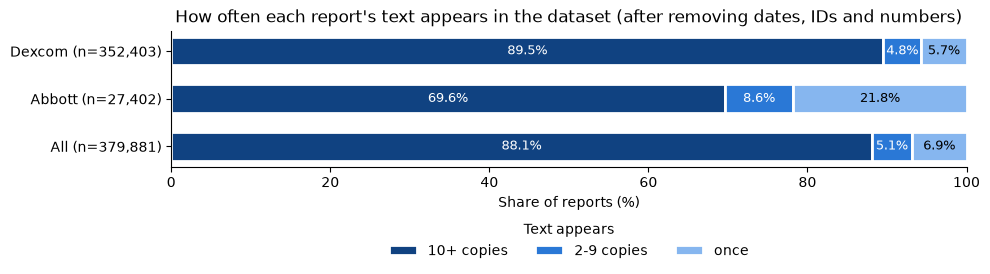

,10+ copies,2-9 copies,once,reports
manufacturer,,,,
Abbott,69.6,8.6,21.8,27402
Dexcom,89.5,4.8,5.7,352403
Other,18.4,34.2,47.4,76
All,88.1,5.1,6.9,379881


,reports,share_%,median_words,top_label,top_label_%
frequency,,,,,
10+ copies,334631,88.1,51.0,A13,28.6
2-9 copies,19187,5.1,86.0,A09,37.2
once,26063,6.9,118.0,A09,49.2


In [18]:
eda.plot_text_frequency_by_brand(df, save_as="text_frequency_by_brand.png")

display(eda.text_frequency_by_brand(df).round(1))
display(eda.text_frequency_summary(df).round(1))

In [19]:
## How much does the complaint phrase decide the label?
phrase_stats, phrases = eda.phrase_summary(df)
display(phrase_stats.round(2))
display(phrases.head(8).round(1))

# Ambiguous phrases: the same words used for different classes
display(phrases[phrases["top_label_%"] < 95].round(1))

reports with a phrase_%            89.38
Dexcom reports with a phrase_%     96.35
distinct phrases                  403.00
phrase predicts label_%            96.63
dtype: float64

,reports,top_label,top_label_%,label_split
phrase,,,,
SIGNAL LOSS,72672,A13,96.4,96% A13
DETACHED OR MISSING SENSOR WIRE,66773,A05,99.3,99% A05
INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) AND THE BLOOD GLUCOSE (BG) METER,60310,A09,99.9,100% A09
TRANSMITTER BATTERY,19421,A09,90.9,91% A09 / 9% A13
ALERT/NOTIFICATION SETTINGS,16634,A16,87.1,87% A16 / 6% A11
EARLY SENSOR EXPIRATION,16624,A16,99.6,100% A16
DEXCOM APP CRASH,14251,A11,99.0,99% A11
PAIRING,12665,A13,97.7,98% A13


,reports,top_label,top_label_%,label_split
phrase,,,,
TRANSMITTER BATTERY,19421,A09,90.9,91% A09 / 9% A13
ALERT/NOTIFICATION SETTINGS,16634,A16,87.1,87% A16 / 6% A11
SENSOR FAILURE,3507,A16,75.2,75% A16 / 23% A09
DISPLAY,2066,A11,52.0,52% A11 / 47% A09
WIRE/NEEDLE/CANNULA DAMAGED OR MISSING,881,A27,58.5,58% A27 / 30% A05 / 11% A04
BLUETOOTH IS OFF WARNING MESSAGE,689,A13,92.7,93% A13 / 7% A11
APPLICATOR DEPLOYMENT,590,A04,72.9,73% A04 / 25% A05


In [20]:
## How far a phrase -> label lookup gets in each class
display(eda.phrase_coverage_by_class(df).round(1))

,reports,with_phrase_%,lookup_correct_%
primary_category,,,
A09,112521,74.9,70.2
A13,102838,99.2,97.2
A05,73061,96.9,95.9
A16,47351,92.7,92.0
A11,19912,98.6,92.5
A04,10625,97.2,92.2
A07,5606,94.7,94.3
A27,4488,61.4,31.6
A24,1330,40.2,39.7


##### Observations:
- **Almost every report is a template.** 88.1% of reports have text that appears 10 or more times (89.5% of Dexcom, 69.6% of Abbott reports). Only 6.9% are one-off texts; they are longer (median 118 words vs 51 for templates) and about half (49.2%) are A09.
- **The complaint phrase almost decides the label.** 89.38% of all reports (96.35% of Dexcom reports) open with "IT WAS REPORTED THAT … OCCURRED", using 403 distinct phrases. Labelling each of them with its phrase's most common label would be right 96.63% of the time: SIGNAL LOSS is A13 in 96.4% of its 72,672 reports, DETACHED OR MISSING SENSOR WIRE is A05 in 99.3%, DEXCOM APP CRASH is A11 in 99.0%.
- **Some phrases are ambiguous.** DISPLAY splits 52% A11 (software) / 47% A09 (output), SENSOR FAILURE 75% A16 / 23% A09, WIRE/NEEDLE/CANNULA DAMAGED OR MISSING 58% A27 / 30% A05 / 11% A04 and APPLICATOR DEPLOYMENT 73% A04 / 25% A05. This answers the course README's question of which labels are harder to distinguish, and it makes sense: a "display" problem can be a software fault or a wrong number on screen.
- **Some classes have no template.** A phrase lookup gets none of A02, A10 or A12 right, and only 31.6% of A27 and 39.7% of A24, because their reports are not in Dexcom's phrase list.

##### Interpretation and implications for model development:
**About 90% of reports are templates where one phrase almost decides the label, so we judge models on rare classes and non-template text, not on overall accuracy.**
1. **Most of the task is phrase recognition.** Any model that finds the phrase will score high accuracy, so a model that is 98–99% accurate may have learned nothing deeper. This is also why TF-IDF + LR looked strong in earlier MAUDE studies.
2. **A strong baseline almost for free.** Besides the majority baseline, section 6 should include a phrase-lookup baseline: phrase → most common training label, otherwise the largest class. What our models have to show is that they beat this lookup on rare classes and one-off text.
3. **The real difficulty sits in three places:** ambiguous phrases, classes with no template (A02, A10, A12, A24–A27, OTHER), and one-off text, where a model actually has to read the report.
4. **A limit on any model.** The 3.4% of phrase reports whose label differs from their phrase's usual label have the same wording, so text alone cannot explain them. The labels probably come from the manufacturer's internal complaint codes mapped to IMDRF, with some reports recoded by hand, so part of the remaining error is label noise rather than model weakness (relevant to the Discussion and to the comparison with human coders).
5. **How to test the BiLSTM and transformer.** Their advantage, reading context (e.g. "alarm did not sound" vs "alarm sounded"), can only show on the roughly 10% of reports that are not pure templates. If we only report overall scores, all three models will look nearly identical, so section 6 should break results down by text frequency (10+ / 2–9 / once, from `eda.text_frequency` computed on the whole dataset) and by manufacturer.

### 2.6 Reports by brand
Checks whether failure types and report style (templated vs free text) differ by brand. `duplicate_%` is the share of a brand's reports whose normalised description is shared with another report of the same brand.

In [21]:
brand_results = eda.brand_summary(df)

# Calculate share of total reports
brand_results["share_%"] = (
    brand_results["reports"] / len(df) * 100
)

# Select the 5 brands with the most reports
top5_summary = brand_results.head(5)

display(top5_summary.round(2))

,reports,duplicate_%,median_words,share_%
brand,,,,
DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,250723,94.42,55.0,66.00
DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,96415,93.41,50.0,25.38
FREESTYLE LIBRE 3 PLUS,8886,78.94,86.0,2.34
FREESTYLE LIBRE 2 PLUS,7105,77.85,112.0,1.87
FREESTYLE LIBRE 3,6246,61.69,158.0,1.64


##### Observations:
Dexcom G7 and G6 together account for 347,138 reports, approximately 91.38% of our entire dataset.
Dexcom reports are also the most repetitive: 94.42% of G7 and 93.41% of G6 reports share their normalised description with another report of the same brand. The FreeStyle Libre products are templated too (78.94% for Libre 3 Plus, 77.85% for Libre 2 Plus and 61.69% for Libre 3), but less so, and their descriptions are longer (median 86–158 words vs 50–55 for Dexcom, partly because many repeat their text, see 2.2).

In [22]:
## Comparing problem categories across the top 5 brands

# Select the top 5 brand-name entries
top5_brands = top5_summary.index

top5_df = df[
    df[config.BRAND_COL].isin(top5_brands)
].copy()

# Calculate percentage distribution within each brand
brand_class_share = pd.crosstab(
    top5_df[config.BRAND_COL],
    top5_df[config.LABEL_COL],
    normalize="index"
) * 100

# Display the percentage table
display(brand_class_share.round(2))

primary_category,A01,A02,A04,A05,A07,A08,A09,A10,A11,A12,A13,A15,A16,A19,A21,A24,A25,A26,A27,NONE
brand_name,,,,,,,,,,,,,,,,,,,,
DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,0.00,0.00,0.75,2.85,0.91,0.01,39.94,0.05,4.23,0.04,29.95,0.00,20.23,0.00,0.00,0.21,0.00,0.00,0.85,0.00
DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM,0.00,0.00,3.90,27.95,1.81,0.00,18.50,0.08,6.29,0.08,28.79,0.00,10.94,0.00,0.00,0.21,0.00,0.00,1.45,0.00
FREESTYLE LIBRE 2 PLUS,0.00,0.38,0.04,0.82,0.13,0.00,95.34,0.00,0.01,0.00,0.04,0.10,0.69,0.00,0.00,2.43,0.01,0.00,0.00,0.00
FREESTYLE LIBRE 3,0.05,2.95,0.14,0.93,0.83,0.00,89.03,0.00,0.11,0.00,0.00,0.08,2.08,0.00,0.00,3.38,0.05,0.03,0.00,0.34
FREESTYLE LIBRE 3 PLUS,0.01,1.59,0.05,0.60,0.26,0.01,94.22,0.00,0.02,0.00,0.00,0.11,0.66,0.01,0.01,2.36,0.02,0.03,0.00,0.03


##### Observations:
The distribution of IMDRF problem categories varies significantly across the major product entries.

Category A09 accounts for 95.34%, 94.22% and 89.03% of reports for FreeStyle Libre 2 Plus, FreeStyle Libre 3 Plus and FreeStyle Libre 3, respectively. 

In contrast, for Dexcom G7, A05 and A13 account for 27.95% and 28.79% of reports respectively, while A09 accounts for only 18.50%, a more varied category distribution. 



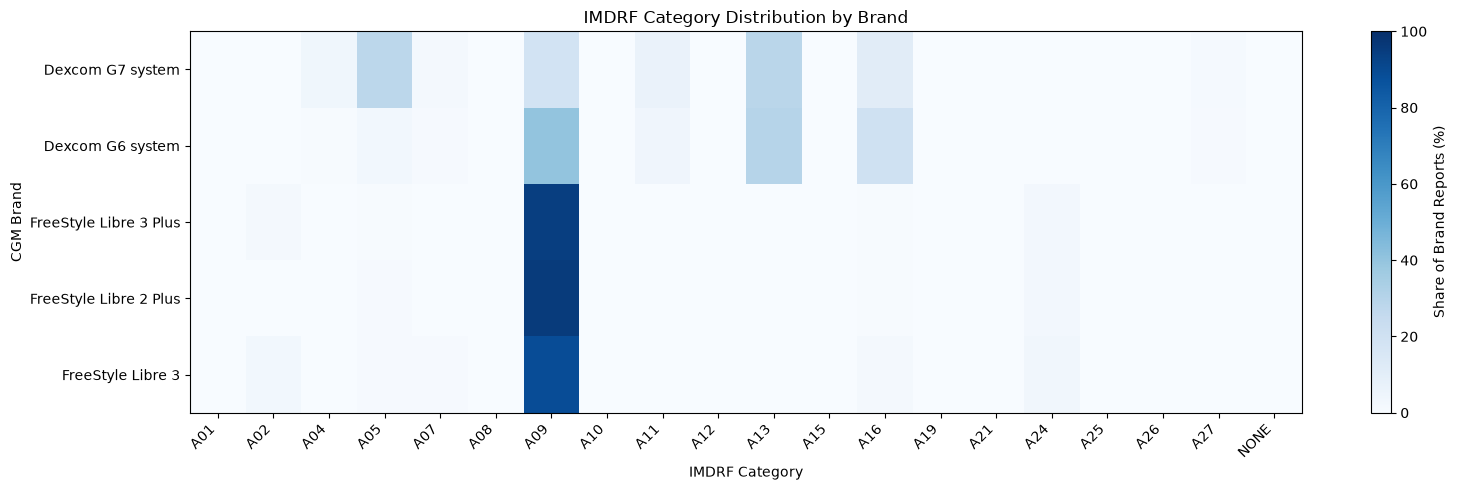

In [23]:
# Create a copy for plotting only
plot_df = top5_df.copy()

# Shorten product names for the graph
short_names = {
    "DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM": "Dexcom G7 system",
    "DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM": "Dexcom G6 system",
    "FREESTYLE LIBRE 3 PLUS": "FreeStyle Libre 3 Plus",
    "FREESTYLE LIBRE 2 PLUS": "FreeStyle Libre 2 Plus",
    "FREESTYLE LIBRE 3": "FreeStyle Libre 3"
}

plot_df["brand_name"] = (
    plot_df["brand_name"].replace(short_names)
)

# Plot using your existing EDA function
eda.plot_brand_by_class(
    plot_df,
    save_as="top5_brand_by_class.png"
)

In [24]:
## Verifying brand concentration

dexcom_reports = (
    top5_summary.loc[
        [
            "DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM",
            "DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM"
        ],
        "reports"
    ].sum()
)

dexcom_percentage = dexcom_reports / len(df) * 100

print(f"Dexcom G6 and G7 reports: {dexcom_reports:,}")
print(f"Share of dataset: {dexcom_percentage:.2f}%")

Dexcom G6 and G7 reports: 347,138
Share of dataset: 91.38%


##### Interpretation:
These findings suggest that both the distribution of reported problems and textual reporting patterns vary across CGM products.
The high concentration of reports among Dexcom products may cause classification models to learn linguistic patterns and category distribution associated with these products more extensively than those of less represented brands. 
In addition, the higher duplication rates among Dexcom reports are consistent with greater reuse of standardised reporting templates. FreeStyle Libre reports are mostly templated too, but they are longer and vary more (2.2, 2.5). 
These differences can affect model generalisation. Models may perform well on frequently repeated reporting patterns, and encounter greater difficulty when classifying less familiar descriptions from other products. 
However, these differences in IMDRF category distributions should not be interpreted as differences in the actual device failure rates. Other factors like reporting practices and product usage may have influenced the number and nature of the submitted reports. 

#### Implications for Model Development:
##### 1. Brand-level evaluation:
Given the large differences in reporting patterns, our project should consider evaluating classification performances across sufficiently represented brands. Comparing per-brand macro-F1 scores could help us identify whether overall model performance is disproportionately influenced by the dominant Dexcom reports.

##### 2. Prevention of data leakage:
The high prevalence of duplicated descriptions reinforces the need to keep all copies of a description in one fold (section 4), so that the same text never appears in both training and test. 

##### 3. Generalisation across reporting styles:
The differences in description length and textual repetition suggest that models should be evaluated on descriptions with varying linguistic characteristics. This is particularly relevant when comparing TF-IDF + Logistic Regression, BiLSTM and transformer models.

##### 4. Brand-name consistency:
The dataset contains variations in product naming conventions, like "DEXCOM G7" and "DEXCOM G7 CONTINUOUS GLUCOSE MONITORING SYSTEM". These entries should be verified before any brand-name standardisation, to avoid incorrectly combining distinct products.
Although brand information will not be used as a predictive input, it may be retained for supplementary performance analysis. These measures aim to improve the reliability of our model evaluations and provide a more meaningful assessment of model generalisation.

### 2.7 Manufacturer narrative
The course README asks whether `manufacturer_narrative` adds signal. It is never a model input (the task allows only `event_description`); this checks what it contains. `redaction_only_%` counts narratives that contain nothing but FDA redaction markers such as "(B)(4)".

In [25]:
narrative_stats, top_narratives = eda.narrative_summary(df)
display(narrative_stats.round(2), top_narratives.round(2))

,reports,empty_%,redaction_only_%,top5_%,median_words
Abbott,27402,3.16,0.00,29.56,363.0
Dexcom,352408,0.53,83.73,84.87,1.0
Other,76,90.79,5.26,100.00,1.0
All,379886,0.74,77.67,79.63,1.0


,family,narrative,reports,share_%
0,Abbott,REPEATED ATTEMPTS BY ADC TO RETRIEVE THE PRODU...,5204,18.99
1,Abbott,,867,3.16
2,Abbott,ADC INVESTIGATED THIS ISSUE AND DETERMINED THA...,844,3.08
3,Abbott,REPEATED ATTEMPTS BY ADC TO RETRIEVE THE PRODU...,614,2.24
4,Abbott,REPEATED ATTEMPTS BY ADC TO RETRIEVE THE PRODU...,571,2.08
5,Dexcom,(B)(4).,269662,76.52
6,Dexcom,(B)(4). (B)(4).,20948,5.94
7,Dexcom,(B)(4). (B)(4). PLEASE DISREGARD INITIAL REPOR...,3850,1.09
8,Dexcom,(B)(4),2733,0.78
9,Dexcom,,1885,0.53


##### Observations and implications:
For most reports the manufacturer narrative carries no information. 83.73% of Dexcom narratives are only redaction markers such as "(B)(4)." (confidential details the FDA removes before publication) and another 0.53% are empty; Dexcom's five most common narratives — redaction markers, an empty narrative and a "please disregard initial reporting" notice — cover 84.87% of its reports. Across the dataset, 78.41% of narratives are empty or redaction-only. Abbott is the opposite: no narrative is redaction-only and the median is 363 words, but much of it is boilerplate too. "REPEATED ATTEMPTS BY ADC TO RETRIEVE THE PRODUCT WERE UNSUCCESSFUL…" alone is 18.99% of Abbott narratives, and the five most common cover 29.56%. Where Abbott narratives do vary, they report the manufacturer's investigation, which is written after the event and would not exist when a new report needs classifying. Adding the narrative would therefore help at most for Abbott's 7% of reports, through text that should not be available at prediction time, so we keep `event_description` as the only input.

### 2.8 Reports with more than one IMDRF category
Informs: evaluating single- and multi-category reports separately (section 6.4).

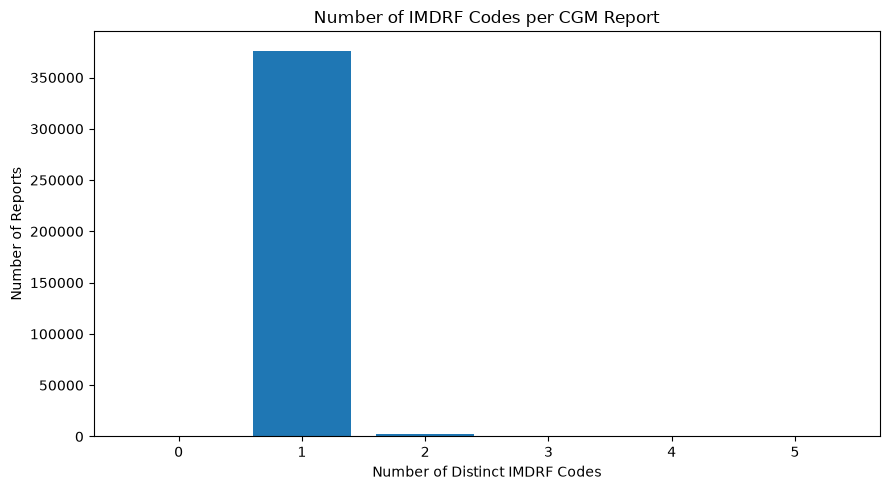

,Number of IMDRF Codes,reports,share_%
0,0,473,0.12
1,1,376233,99.04
2,2,2770,0.73
3,3,319,0.08
4,4,77,0.02
5,5,14,0.00


In [26]:
eda.plot_imdrf_code_counts(df[config.IMDRF_COL], save_as="imdrf_codes.png")


# Count distinct IMDRF codes for each report
code_counts = eda.count_imdrf_codes(
    df[config.IMDRF_COL]
)

# Create frequency table
code_summary = (
    code_counts.value_counts()
    .sort_index()
    .rename_axis("Number of IMDRF Codes")
    .reset_index(name="reports")
)

# Calculate percentage of total reports
code_summary["share_%"] = (
    code_summary["reports"] / len(df) * 100
)

display(code_summary.round(2))

##### Observations:
The results above reveal that a vast majority (99.04%) of CGM adverse event reports contain only one recognised IMDRF code. Only 3,180 reports (0.84%) contain two or more codes. 2,770 reports contain two codes, 319 contain three codes, 77 contain four codes, and only 14 contain five codes.
Additionally, 473 reports (0.12%) have no recognised IMDRF codes, requiring further investigation to determine whether this reflects missing information or limitations in code extraction.


In [27]:
## Comparing single-code vs multi-code reports

# Count reports by type
zero_codes = (code_counts == 0).sum()
single_code = (code_counts == 1).sum()
multi_code = (code_counts >= 2).sum()

# Display counts and percentages
comparison = pd.DataFrame({
    "Report Type": [
        "No recognised code",
        "Single-code",
        "Multi-code"
    ],
    "Reports": [
        zero_codes,
        single_code,
        multi_code
    ]
})

comparison["share_%"] = (
    comparison["Reports"] / len(df) * 100
)

display(comparison.round(2))

,Report Type,Reports,share_%
0,No recognised code,473,0.12
1,Single-code,376233,99.04
2,Multi-code,3180,0.84


#### Interpretation:
The substantial dominance of single-code reports suggests that most reports are associated with one coded problem category.
Reports containing multiple IMDRF codes may present additional classification challenges, as their descriptions could contain information associated with several device problems.

Since our models are designed to predict only one primary_category for each report, 
descriptions involving multiple problems may introduce ambiguity when determining the appropriate primary classification label.

Furthermore, given the small proportion of multi-code reports, the overall model performance may not adequately reflect classification performance on this subgroup. Nevertheless, whether multi-code reports are actually more challenging to classify remains to be determined through model evaluation.

#### Implications for Model Development:
To investigate whether classification performance differs between single-code and multi-code reports, our project will conduct supplementary evaluation on these two groups separately.

In **Section 6.4**, the macro-F1 scores of TF-IDF + Logistic Regression, BiLSTM and the fine-tuned transformer will be compared across single-code and multi-code reports using the out-of-fold predictions (every report is predicted once, by a model that never saw it).

This analysis will help determine whether the presence of multiple reported problem categories is associated with differences in classification performance.
However, given the relatively small number of multi-code reports, subgroup results will be interpreted cautiously, particularly for categories with limited representation.

More importantly, our project will retain its original single-label classification objective, predicting primary_category solely from event_description. The number of IMDRF codes will be used only for supplementary evaluation rather than as an additional predictive feature.

### 2.9 Distinctive words and phrases per category
Informs: text-cleaning steps and the TF-IDF n-gram range.

Terms are ranked by a one-vs-rest chi-square test on one copy of each distinct normalised description, keeping only terms more common in the category than in the rest (categories with at least 20 distinct descriptions).

In [28]:
distinctive_terms = eda.distinctive_terms_per_class(df[config.TEXT_COL], df[config.LABEL_COL], k=15)
display(distinctive_terms)

,A09,A13,A05,A16,A27,A04,A24,A07,A02,A11,NONE,A15,A10,A12,A26,A08
0,grid,signal loss,detached,alert notification,wearable failure,broken,skin reaction,receiver shutdown,smoke,crash,reference,unspecified insertion,overheating,transmitter unpaired,not consent,paired app
1,parkes,signal,reported detached,notification,unspecified malfunction,broken sensor,reaction,unexpected receiver,explosion,app crash,sensors,insertion issue,sensor overheating,unpaired,device deficiency,arrived failed
2,parkes error,reported signal,missing sensor,notification settings,malfunction,reported broken,skin,shutdown,report smoke,crash occurred,reference report,appears ongoing,receiver overheating,unpaired data,consent follow,not saved
3,error grid,loss occurred,missing,reported alert,reported wearable,wire,prescribed,unexpected,explosion shock,reported dexcom,dexcom,worked using,overheating no,unpaired product,customer actively,days wore
4,values,loss,detached missing,settings issue,failure occurred,sensor wire,infection,shutdown occurred,smoke explosion,dexcom app,dexcom sensors,insert taking,overheating sensor,unpaired no,deficiency report,continued extremely
5,meter,hour,wire,settings,sensor issue,broken needle,reaction reported,reported unexpected,reports,smart device,reference reports,arm evidenced,overheating product,cause unable,consent,times days
6,zone,finding signal,wire occurred,alert,malfunction occurred,wire occurred,experienced skin,downloaded,shock no,smart,replacements,using normal,transmitter overheating,unable determined,suggested adc,changed freestyle
7,glucose,loss hour,sensor wire,alarm,brief sensor,cause broken,reported skin,receiver log,customer reports,indicated operating,hope,cgm consecutive,overheating shocking,reported transmitter,reasonably suggested,used calibration
8,fall,transmitter app,received determined,speaker,error brief,reported applicator,adverse skin,not downloaded,reports abbott,operating smart,company,placing punch,shocking,investigation confirmation,allegation device,abroad
9,fall zone,hour investigation,mdr product,vibrator,brief,confirmed broken,wear abbott,log not,shock,supported misuse,insurance,probe needle,exterior visual,confirmation complaint,clarification available,sensor wouldn


#### Method
The first version of this analysis ranked terms by raw frequency over all reports. Those lists were dominated by boilerplate shared by every category ("reported", "no", "not", "no injury", "medical intervention") and by the year "2025", which was a top term for A04 and A05 only because their templates state the sensor insertion date. This version therefore:
- counts each distinct description once, so a template repeated 27,000 times does not outweigh everything else;
- removes numbers, dates, years and redaction markers;
- ranks terms by how specific they are to a category (chi-square) instead of how frequent they are, so phrases every category shares rank low.

#### Observations:
The lists now name the actual device problems: A09 "parkes error grid", "meter" (glucose accuracy); A13 "signal loss"; A05 "detached", "missing sensor"; A16 "alert notification settings"; A04 "broken sensor wire"; A07 "unexpected receiver shutdown"; A11 "app crash"; A10 "overheating"; A12 "transmitter unpaired"; A02 "smoke", "explosion"; A24 "skin reaction"; A27 "wearable failure", "unspecified malfunction". Many of the most distinctive terms are bigrams, and most come from the template's opening sentence ("IT WAS REPORTED THAT A … OCCURRED").

#### Implications for Model Development:
##### 1. TF-IDF n-gram selection:
Our project will investigate both unigram-only **(ngram_range=(1, 1))** and combined unigram-bigram **(ngram_range=(1, 2))** representations. Bigrams such as "signal loss" and "error grid" capture more specific information than their words alone. The final configuration will be selected based on cross-validation macro-F1.

##### 2. Text preprocessing:
Years, dates, IDs and redaction markers will be masked during cleaning. A year says when a report was filed, not what went wrong, and a model could learn the reporting period instead of the problem. Negation terms such as "no" and "not" will be kept, and aggressive stop-word removal will be avoided: TF-IDF already down-weights boilerplate that appears in every report.

##### 3. Influence of duplicate templates:
Given the high prevalence of near-duplicate descriptions identified in **Section 2.4**, keeping all copies of a description in one fold (section 4) reduces the risk of models achieving inflated evaluation performance through memorisation of repeated templates.

### 2.10 Summary: decisions for cleaning and the folds

| Finding | Decision | Applied in |
|---|---|---|
| NONE reports have no IMDRF code or problem term (2.1) | Drop them (473 reports): the label is missing | 3. Cleaning |
| A24–A27 all mean no identified device problem; the course README groups them (2.1) | Merge into one class, `A24-A27` | 3. Cleaning |
| Classes with fewer than ~40 test reports give unreliable F1 (2.1) | Merge classes with fewer than `MIN_CLASS_COUNT` = 150 training reports into OTHER (12 classes remain) | 3. Cleaning, `config.py` |
| 4 empty descriptions; short ones are still informative (2.3) | Drop the empty ones, keep the short ones | 3. Cleaning |
| 93% of reports share their description with other reports (2.4, 2.5) | Keep all copies of a cleaned text in one fold; cut texts with more than 200 copies to 200; each fold is the test set once | 3. Cleaning, 4. Folds |
| Years, dates, IDs and redaction markers rank as class terms (2.9) | Mask them in `cleaning.clean_text` | 3. Cleaning |
| 45.7% of Abbott reports repeat their whole description; after cleaning, 96.3% of reports fit in 128 words and 99.2% in 256 (2.2), but after the copy cap (section 3) only 89.9% fit in 128 and 98.1% in 256, because the cap makes long free text a bigger share | Keep one copy of a repeated description; fix the BiLSTM's `MAX_LEN` at 256 words (no tuning); the transformer's length in sub-word tokens is decided in 5.3 | 3. Cleaning, 4. Folds |
| About 90% of reports are templates whose complaint phrase predicts the label 96.6% of the time (2.5) | Add a phrase-lookup baseline next to the majority baseline | 6.1 |
| Model differences can only show on rare classes and non-template text; category mix, style and length differ by brand (2.2, 2.5, 2.6) | Report macro-F1 by text frequency (10+ / 2–9 / once) and by manufacturer | 6 |
| Manufacturer narrative is mostly redaction markers or boilerplate (2.7) | Keep `event_description` as the only input | — |

## 3. Data cleaning (Suling)

Steps chosen from the analysis in section 2 (summary in 2.10); the code is in `src/data/cleaning.py`. All steps are fixed rules applied to the whole dataset before the folds are made.
- **Rows:** drop reports labelled NONE (the label is missing) and reports with no text left after cleaning.
- **Labels:** merge A24–A27 into one class. Classes with fewer than `MIN_CLASS_COUNT` = 150 training reports per turn (150 / 0.8 ≈ 188 reports in the whole dataset) become OTHER, decided once so every fold has the same 12 classes.
- **Text:** lowercase; remove redaction markers such as "(B)(6)", report and field-action IDs, dates, times and years; replace other numbers (glucose values, FDA codes) with "num"; expand abbreviations (CGM, BG, HCP, ADC, DKA, mg/dL, mmol/L, EGV, ER, ICU, EMS, IV, PT, OS), dropping "(CGM)"-style definitions so the words are not repeated; repair mis-encoded apostrophes ("WASN�T"); keep negations and punctuation; no stemming or stop-word removal.
- **Copies:** a cleaned text that appears more than `MAX_COPIES_PER_TEXT` = 200 times is cut to 200 randomly chosen copies, so no single template makes one fold much heavier in its class (section 4).

In [4]:
## What clean_text does to three typical reports: a Dexcom template, an Abbott template and free text
examples = pd.concat([
    df[config.TEXT_COL][df[config.TEXT_COL].str.contains(pattern, regex=False, na=False)].head(1)
    for pattern in ["(CGM)", "MG/DL", "WASN\ufffdT"]
])

with pd.option_context("display.max_colwidth", 400):
    display(pd.DataFrame({"raw": examples, "cleaned": examples.map(cleaning.clean_text)}))

,raw,cleaned
105,IT WAS REPORTED THAT AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) AND THE BLOOD GLUCOSE (BG) METER OCCURRED. THE SENSOR WAS INSERTED INTO THE ARM ON (B)(6) 2024. DATA WAS EVALUATED AND THE ALLEGATION WAS UNDETERMINED. THE PROBABLE CAUSE COULD NOT BE DETERMINED VIA DATA. THE REPORTED GLUCOSE VALUES FALL WITHIN THE D ZONE OF THE PARKES ERROR GRID. THE DATA INVESTIGATION DID NOT FIN...,it was reported that an inaccuracy between the continuous glucose monitor and the blood glucose meter occurred. the sensor was inserted into the arm on . data was evaluated and the allegation was undetermined. the probable cause could not be determined via data. the reported glucose values fall within the d zone of the parkes error grid. the data investigation did not find blood glucose calibr...
25,"A CUSTOMER REPORTED RECEIVING ERRONEOUS GLUCOSE RESULTS FROM AN ABBOTT DIABETES CARE DEVICE. THE CUSTOMER RECEIVED SENSOR SCAN RESULTS OF 53MG/DL COMPARED TO READINGS OF 153MG/DL RESPECTIVELY OBTAINED ON A ADC METER AND THE RESULTS, WHEN PLOTTED ON A PARKES ERROR GRID, FALL INTO THE C ZONE, SHOWING THE DIFFERENCE IN VALUES TO BE CLINICALLY SIGNIFICANT. THE LENGTH OF SENSOR WEAR WAS 9 DAYS. THE...","a customer reported receiving erroneous glucose results from an abbott diabetes care device. the customer received sensor scan results of num milligrams per decilitre compared to readings of num milligrams per decilitre respectively obtained on a abbott diabetes care meter and the results, when plotted on a parkes error grid, fall into the c zone, showing the difference in values to be clinica..."
67,"DEXCOM G7 CGM SENSOR ISSUES. CONSTANT WRONG READINGS. FAILURE TO EJECT WHEN APPLYING SENSOR, OFTEN SHOWS READINGS IN THE 309S..I HAVE AN A1C OF 6 ALMOST ALL THE TIME. I'LL COMPARE MY SENSOR WITH MY GLUCOMETER AND THERE CAN BE A DIFFERENCE OF 100 IN THE READINGS. 2 NIGHTS AGO, MY PUMP ALERTED ME TO A LOW READING OF 49 MY GLUCOMETER SHOWED I WAS AT 129. FALSE HIGH AND LOW READINGS POSE A DANGER ...","dexcom g7 continuous glucose monitor sensor issues. constant wrong readings. failure to eject when applying sensor, often shows readings in the 309s..i have an a1c of num almost all the time. i'll compare my sensor with my glucometer and there can be a difference of num in the readings. num nights ago, my pump alerted me to a low reading of num my glucometer showed i was at num . false high an..."


In [5]:
n_reports = len(df)
df = cleaning.clean_reports(df)
print(f"Dropped {n_reports - len(df)} reports (NONE label or no text left after cleaning)")

# Rare classes -> OTHER, decided once on the whole dataset:
# fewer than MIN_CLASS_COUNT training reports per turn = fewer than MIN_CLASS_COUNT / (1 - TEST_SIZE) reports in all
keep = cleaning.frequent_classes(df[config.LABEL_COL], config.MIN_CLASS_COUNT / (1 - config.TEST_SIZE))
df[config.LABEL_COL] = cleaning.merge_rare_classes(df[config.LABEL_COL], keep)
print(f"{len(keep) + 1} classes: {', '.join(keep)} and OTHER")

# Cut every text with more than MAX_COPIES_PER_TEXT copies to that many random copies
before_cap = df[config.LABEL_COL].value_counts()
df = cleaning.cap_copies(df)
after_cap = df[config.LABEL_COL].value_counts()
display(pd.DataFrame({"reports": before_cap, "after cap": after_cap,
                      "kept %": after_cap / before_cap * 100}).round(1))
print(f"Kept {len(df):,} of {before_cap.sum():,} reports ({len(df) / before_cap.sum():.1%})")

Dropped 477 reports (NONE label or no text left after cleaning)
12 classes: A02, A04, A05, A07, A09, A10, A11, A12, A13, A16, A24-A27 and OTHER


,reports,after cap,kept %
primary_category,,,
A02,936,935,99.9
A04,10625,6044,56.9
A05,73061,22166,30.3
A07,5606,2211,39.4
A09,112520,56407,50.1
A10,241,240,99.6
A11,19912,4587,23.0
A12,239,216,90.4
A13,102836,25705,25.0


Kept 141,212 of 379,409 reports (37.2%)


## 4. Folds: the train/test rotation (Suling)

Every report goes into one of 5 folds (`src/data/splitting.py`). Each fold is the test set once while the models train on the other four (section 5), so every report is predicted once, by a model that never saw it. There is no separate fixed 80/20 test set; README.md explains why.
- **Templates** (a cleaned text that appears 2 or more times): all copies of the text go into the same fold, so a model is never tested on a text it trained on. Groups are placed largest first, each in the fold that so far has the fewest reports of the group's class.
- **Free text** (a cleaned text that appears once): spread over the folds at random, stratified by class.

Each class should have about 20% of its reports in each fold. A10 and A12 vary more (about 10–33%), because each has one or two texts with 60+ copies among only about 240 reports; we accept this and treat their per-fold scores as noisy.

In [6]:
df["fold"] = splitting.assign_folds(df)
folds = splitting.fold_positions(df["fold"])  # (training positions, test positions) for each turn

# Share of each class's reports in each fold (ideally 20% everywhere)
display(splitting.fold_summary(df, df["fold"]).round(1))

X, y = df[config.TEXT_COL], df[config.LABEL_COL]

# Fixed input length in words for the BiLSTM (no tuning). The copy cap makes long free text a
# bigger share, so 128 words would fit only ~90% of the capped reports; 256 fits ~98%.
# The transformer's input length (in sub-word tokens) is decided in 5.3.
MAX_LEN = 256
n_words = X.map(lambda text: len(tokenize(text)))
print(f"Reports within 128 / {MAX_LEN} words: {(n_words <= 128).mean():.1%} / {(n_words <= MAX_LEN).mean():.1%}")

,fold 0,fold 1,fold 2,fold 3,fold 4,reports
primary_category,,,,,,
ALL,20.0,20.0,20.0,20.0,20.0,141212
A09,20.0,20.0,20.0,20.0,19.9,56407
A13,20.0,19.9,20.0,20.0,20.1,25705
A05,20.1,20.0,20.0,19.9,20.0,22166
A16,19.9,20.2,19.9,20.1,19.9,17458
A04,19.6,19.9,20.3,20.4,19.8,6044
A24-A27,20.4,19.7,20.0,19.2,20.7,5020
A11,20.1,19.6,19.7,20.1,20.5,4587
A07,20.1,20.3,19.9,19.7,19.9,2211


Reports within 128 / 256 words: 89.9% / 98.1%


## 5. Models

Every model has the same methods (`src/interfaces.py`): `fit(texts, labels)`, `predict(texts)`, `predict_proba(texts)`, `save(path)` and `load(path)`. Each model is trained 5 times, once per turn of the rotation, on the four training folds, and predicts the fold left out (`cross_validation.out_of_fold_proba`). Settings are fixed (no hyper-parameter tuning). All use class weighting for the imbalance. With `TRAIN = False`, each model's 5 saved versions are loaded from `weights/` instead.

In [ ]:
## With TRAIN = False the models are loaded from weights/: first download any weight files missing there
# (from the Google Drive folder config.WEIGHTS_URL; files already in weights/ are never overwritten)
if not TRAIN:
    loading.download_weights()

### 5.1 TF-IDF + Logistic Regression (James)

Word/phrase counts weighted by TF-IDF, then logistic regression with balanced class weights. Fixed settings: unigrams and bigrams, regularisation strength `C` = 1.

In [ ]:
def tfidf_path(k):
    return config.WEIGHTS_DIR / f"tfidf_lr_fold{k}.joblib"

def make_tfidf():
    return TfidfLR(ngram_range=(1, 2), C=1.0)

tfidf_proba = cross_validation.out_of_fold_proba(make_tfidf, X, y, folds, model_path=tfidf_path,
                                                 train=TRAIN, load_model=TfidfLR.load)

TfidfLR.load(tfidf_path(0)).top_features(k=10)  # turn 0's model; compare with the phrases in section 2.9

### 5.2 Bidirectional LSTM (Suling)

Word embeddings learned from scratch (128 numbers per word) → BiLSTM reading the first 256 words forwards and backwards (128 + 128 numbers per word) → attention pooling (a learned weight per word, as in Li et al. 2024) → linear layer → 12 class scores (`src/models/bilstm.py`).

- **Training** (`src/models/torch_training.py`, shared with the transformer): class-weighted cross-entropy, dropout 0.3, learning rate 0.001, batch size 64, up to 10 epochs.
- **Early stopping:** about 10% of each turn's training folds is held out as a validation set, built with the same rule as the folds (all copies of a text on one side), so it measures new text rather than memory. Training stops after 2 epochs without a better validation macro-F1 and keeps the best epoch. The test fold is never used.
- **Saved per turn** in `weights/`: `bilstm_fold{k}.pt` (settings, vocabulary, weights) and `bilstm_fold{k}_history.csv` (loss and validation macro-F1 per epoch).

Fixed settings, no tuning. Needs a GPU (Colab) for the full data.

In [8]:
def bilstm_path(k):
    return config.WEIGHTS_DIR / f"bilstm_fold{k}.pt"

def make_bilstm():
    return BiLSTMClassifier(max_len=MAX_LEN, hidden_dim=128, dropout=0.3, epochs=10, patience=2, device=device)

def load_bilstm(path):
    return BiLSTMClassifier.load(path, device=device)

bilstm_proba = cross_validation.out_of_fold_proba(make_bilstm, X, y, folds, model_path=bilstm_path,
                                                  train=TRAIN, load_model=load_bilstm)

turn 0: loading the saved model from /content/IT1244-Group-Project/weights/bilstm_fold0.pt
turn 1: training
  epoch 1: train loss 0.5176, val macro-F1 0.8585 (52s)
  epoch 2: train loss 0.2854, val macro-F1 0.8692 (51s)
  epoch 3: train loss 0.2370, val macro-F1 0.8718 (51s)
  epoch 4: train loss 0.2059, val macro-F1 0.8688 (51s)
  epoch 5: train loss 0.1856, val macro-F1 0.8660 (51s)
  early stopping: best val macro-F1 0.8718
turn 2: training
  epoch 1: train loss 0.5041, val macro-F1 0.8536 (52s)
  epoch 2: train loss 0.2802, val macro-F1 0.8598 (51s)
  epoch 3: train loss 0.2232, val macro-F1 0.8683 (51s)
  epoch 4: train loss 0.1946, val macro-F1 0.8835 (51s)
  epoch 5: train loss 0.1776, val macro-F1 0.8637 (51s)
  epoch 6: train loss 0.1647, val macro-F1 0.8692 (51s)
  early stopping: best val macro-F1 0.8835
turn 3: training
  epoch 1: train loss 0.4892, val macro-F1 0.8305 (52s)
  epoch 2: train loss 0.2681, val macro-F1 0.8513 (51s)
  epoch 3: train loss 0.2110, val macro-F1 0

In [ ]:
## Training curves of the 5 turns, from the history file saved next to each turn's weights
bilstm_histories = [pd.read_csv(bilstm_path(k).with_name(f"{bilstm_path(k).stem}_history.csv"))
                    for k in range(config.N_FOLDS)]
plot_training_curves(bilstm_histories, "BiLSTM", save_as="bilstm_training_curves.png")

### 5.3 Fine-tuned transformer (Suling)

A pretrained transformer with a new classification layer, fine-tuned on our reports with the same training code as the BiLSTM. **Placeholder:** planned after the BiLSTM (model, input length in sub-word tokens, training settings).

In [ ]:
def transformer_path(k):
    return config.WEIGHTS_DIR / f"transformer_fold{k}"

TRANSFORMER_MODEL = DISTILBERT       # or CLINICAL_BERT
TRANSFORMER_TRAIN_SAMPLES = 50_000   # stratified sample per turn to save compute; None = all training reports

def make_transformer():
    return TransformerClassifier(model_name=TRANSFORMER_MODEL,
                                 max_len=256,  # in sub-word tokens; to be decided in 5.3
                                 device=device)

def load_transformer(path):
    return TransformerClassifier.load(path, device=device)

transformer_proba = cross_validation.out_of_fold_proba(
    make_transformer, X, y, folds, model_path=transformer_path, train=TRAIN,
    load_model=load_transformer, max_train_reports=TRANSFORMER_TRAIN_SAMPLES)

## 6. Evaluation (Lucas)

Every report is predicted once, by the model of the turn in which its fold was the test set (out-of-fold predictions from section 5). Main metric is **macro-F1** (every category counts equally, so a model cannot score well by ignoring rare failure types).

### 6.1 Overall comparison

The first row is the majority baseline (`src/evaluation/baseline.py`), which always predicts the most common training category. It is the minimum bar every model must beat, and its high accuracy but very low macro-F1 shows why macro-F1 is the main metric. The first table shows macro-F1 in each turn, with the mean and spread over the 5 turns; the second scores all out-of-fold predictions together.

In [ ]:
baseline_proba = cross_validation.out_of_fold_proba(MajorityBaseline, X, y, folds)  # instant, not saved

probabilities = {"Majority baseline": baseline_proba, "TF-IDF + LR": tfidf_proba,
                 "BiLSTM": bilstm_proba, "Transformer": transformer_proba}
predictions = {name: proba.idxmax(axis=1) for name, proba in probabilities.items()}

# Macro-F1 in each turn, then the mean and spread over the 5 turns
by_turn = pd.DataFrame({name: metrics.macro_f1_by_group(y, pred, df["fold"])
                        for name, pred in predictions.items()}).T
by_turn["mean"], by_turn["std"] = by_turn.mean(axis=1), by_turn.std(axis=1)
display(by_turn.round(3))

# All out-of-fold predictions together
pd.DataFrame({name: metrics.scores(y, pred) for name, pred in predictions.items()}).T

### 6.2 Per-class results and confusion matrices

In [ ]:
for name, file_name in [("TF-IDF + LR", "confusion_tfidf.png"),
                        ("BiLSTM", "confusion_bilstm.png"),
                        ("Transformer", "confusion_transformer.png")]:
    print(name)
    display(metrics.per_class_report(y, predictions[name]))
    metrics.plot_confusion_matrix(y, predictions[name], title=name, save_as=file_name)

### 6.3 Macro-F1 by brand

In [ ]:
pd.DataFrame({name: metrics.macro_f1_by_group(y, pred, df[config.BRAND_COL])
              for name, pred in predictions.items()})

### 6.4 Macro-F1 on single- vs multi-category reports

In [ ]:
is_multi = eda.count_imdrf_codes(df[config.IMDRF_COL]) > 1
report_type = np.where(is_multi, "multi-category", "single-category")
pd.DataFrame({name: metrics.macro_f1_by_group(y, pred, report_type)
              for name, pred in predictions.items()})

### 6.5 Comparison with previous MAUDE studies

| Study | Data | Task | Best reported |
|---|---|---|---|
| Wang et al. 2019 | 5,588 MAUDE reports, balanced | binary (health-IT or not) | LR F1 0.859; SVM+LR+CNN F1 0.870 |
| Li et al. 2024 | 4,568 da Vinci reports | binary (harm or not) | BiLSTM-attention F1 85.37; BERT 78.61 |
| Luschi et al. 2023 | 3,075 labelled MAUDE reports | binary (health-IT or not) | fine-tuned ClinicalBERT |
| **Ours** | CGM MAUDE reports | multi-class IMDRF category | see 6.1 |

These studies used smaller datasets and binary labels, so the numbers are a rough reference, not a like-for-like comparison.

## 7. Discussion

TODO: which model is best and why (with evidence from 6.1-6.4), where models fail, comparison with human coders, and societal impact (privacy, fairness across brands, interpretability, jobs).